In [219]:
import os
import pandas as pd
import numpy as np
import librosa
import matplotlib.pyplot as plt
import librosa.display
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
import tensorflow.keras.backend as K
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, classification_report
from sklearn.utils import class_weight
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import seaborn as sns
import time
from sklearn.metrics import roc_auc_score

---

**Dataset 1 (one hive)**

In [ ]:
with_queen_dir = r"data/recordings/queen_present"
no_queen_dir   = r"data/recordings/queen_absent"

In [161]:
'''
build the dataset from the file names in the folders and assign the class based on the folder:
queenbee_present - 1
queenbee_absent - 0
'''

data = []

# queen present = 1
for i in os.listdir(with_queen_dir):
    if i.lower().endswith((".wav")):
        data.append([i, 1])

#  queen absent = 0
for i in os.listdir(no_queen_dir):
    if i.lower().endswith((".wav")):
        data.append([i, 0])

df = pd.DataFrame(data, columns=["file", "label"])

In [162]:
df.head()

,file,label
0,Hive1 12_06_2018_QueenBee____00_00_00_chunk1.wav,1
1,Hive1 12_06_2018_QueenBee____00_00_00_chunk10.wav,1
2,Hive1 12_06_2018_QueenBee____00_00_00_chunk11.wav,1
3,Hive1 12_06_2018_QueenBee____00_00_00_chunk12.wav,1
4,Hive1 12_06_2018_QueenBee____00_00_00_chunk13.wav,1


In [ ]:
df.to_csv("data/labels.csv", index=False)

In [164]:
df['label'].value_counts()

label
1    4000
0    2000
Name: count, dtype: int64

In [ ]:
audio = "data/recordings/all" # folder with all recordings (present + absent)

print(df.shape)
df.head()

(6000, 2)


,file,label
0,Hive1 12_06_2018_QueenBee____00_00_00_chunk1.wav,1
1,Hive1 12_06_2018_QueenBee____00_00_00_chunk10.wav,1
2,Hive1 12_06_2018_QueenBee____00_00_00_chunk11.wav,1
3,Hive1 12_06_2018_QueenBee____00_00_00_chunk12.wav,1
4,Hive1 12_06_2018_QueenBee____00_00_00_chunk13.wav,1


In [ ]:
# check the sampling rate (sr)

audio_p = "data/recordings/all/example_clip.wav"

y, sr = librosa.load(audio_p, sr=None)
print(sr)

32000


In [ ]:
def generate_and_save_spectrograms(
        df, 
        audio_dir, 
        output_dir, 
        sr=32000, 
        n_mels=128, 
        target_duration=10
    ):

    os.makedirs(output_dir, exist_ok=True)

    target_length = sr * target_duration
    new_rows = []

    for idx, row in df.iterrows():
        file_name = row["file"]
        label = row["label"]

        audio_path = os.path.join(audio_dir, file_name)

        if not os.path.exists(audio_path):
            print(f"Audio not found: {audio_path}")
            continue

        # load the file
        signal, _ = librosa.load(audio_path, sr=sr)

        # fix the length to 10 seconds (trim if too long, pad with zeros if too short)
        if len(signal) < target_length:
            signal = np.pad(signal, (0, target_length - len(signal)))
        else:
            signal = signal[:target_length]

        # mel spectrogram
        mel = librosa.feature.melspectrogram(y=signal, sr=sr, n_mels=n_mels)

        mel_db = librosa.power_to_db(mel, ref=np.max)

        # convert to dB, then scale to 0-1
        mel_db = (mel_db - mel_db.min()) / (mel_db.max() - mel_db.min())

        # save
        out_name = file_name.replace(".wav", ".npy")
        out_path = os.path.join(output_dir, out_name)
        np.save(out_path, mel_db)

        new_rows.append([out_name, label])

    # return the dataframe
    new_df = pd.DataFrame(new_rows, columns=["file", "label"])
    return new_df

In [ ]:

spectrogram_dir = "data/spectrograms"

df_specs = generate_and_save_spectrograms(
    df=df,
    audio_dir=audio,
    output_dir=spectrogram_dir,
    sr=32000,
    n_mels=128,
    target_duration=10
)

df_specs.head()

,file,label
0,Hive1 12_06_2018_QueenBee____00_00_00_chunk1.npy,1
1,Hive1 12_06_2018_QueenBee____00_00_00_chunk10.npy,1
2,Hive1 12_06_2018_QueenBee____00_00_00_chunk11.npy,1
3,Hive1 12_06_2018_QueenBee____00_00_00_chunk12.npy,1
4,Hive1 12_06_2018_QueenBee____00_00_00_chunk13.npy,1


In [ ]:
# helper used only to preview spectrograms (plots a mel spectrogram)

def show_mel_spec(file_name):
    file_path = os.path.join(spectrogram_dir, file_name)

    if not os.path.exists(file_path):
        print("File does not exist:", file_path)
        return
    
    # load the spectrogram from .npy
    mel = np.load(file_path)
    print("Shape mel:", mel.shape)

    # label
    label = df_specs[df_specs["file"] == file_name]["label"].values[0]

    plt.figure(figsize=(10, 4))
    plt.imshow(mel.squeeze(), aspect="auto", origin="lower", cmap="magma")
    plt.colorbar()
    plt.title(f"{file_name}  |  class = {label}")
    plt.xlabel("Frames")
    plt.ylabel("Mel bands")
    plt.show()

Shape mel: (128, 626)


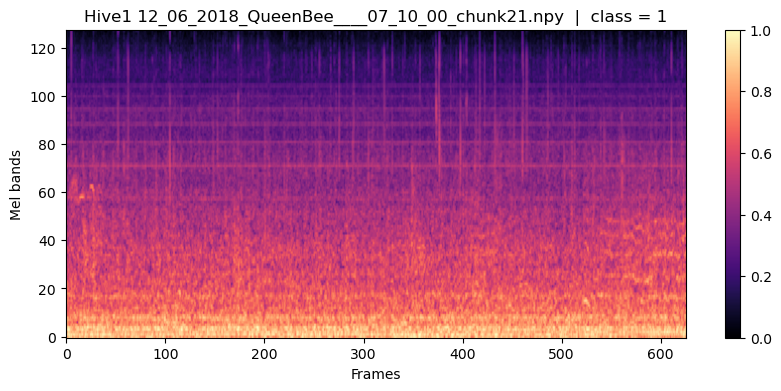

In [ ]:
# import random to preview different spectrograms
import random

random_file = random.choice(df_specs["file"].tolist())
show_mel_spec(random_file)

In [ ]:
# split the data into train / validation / test
train_df, temp_df = train_test_split(df_specs, test_size=0.20, random_state=42, stratify=df_specs["label"])
val_df, test_df  = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df["label"])

In [ ]:
# size of each split
print("Train:", train_df.shape)
print("Val:",   val_df.shape)
print("Test:",  test_df.shape)

Train: (4800, 2)
Val: (600, 2)
Test: (600, 2)


In [173]:
# class distribution in the training and validation sets
print(train_df['label'].value_counts())

print(val_df['label'].value_counts())

label
1    3200
0    1600
Name: count, dtype: int64
label
1    400
0    200
Name: count, dtype: int64


In [174]:
# loads the .npy spectrograms from disk and builds the (X, y) arrays for the model

def load_spectrogram_dataset(df, spectrogram_dir):
    X = []
    y = []

    for _, row in df.iterrows():
        file_name = row["file"]
        label = row["label"]

        spec_path = os.path.join(spectrogram_dir, file_name)

        if not os.path.exists(spec_path):
            print("Missing:", spec_path)
            continue

        mel = np.load(spec_path)

        # channel dimension
        mel = mel[..., np.newaxis]

        X.append(mel)
        y.append(label)

    return np.array(X), np.array(y)

In [177]:
X_train, y_train = load_spectrogram_dataset(train_df, spectrogram_dir)
X_val,   y_val   = load_spectrogram_dataset(val_df,   spectrogram_dir)
X_test,  y_test  = load_spectrogram_dataset(test_df,  spectrogram_dir)

In [178]:
print(X_train.shape)  
print(X_val.shape)
print(X_test.shape)

(4800, 128, 626, 1)
(600, 128, 626, 1)
(600, 128, 626, 1)


In [ ]:
# save the splits
np.save("X_train.npy", X_train)
np.save("X_val.npy", X_val)
np.save("X_test.npy", X_test)
np.save("y_train.npy", y_train)
np.save("y_val.npy", y_val)
np.save("y_test.npt", y_test)

In [ ]:
# load the saved splits so the split is not redone on every run
X_train = np.load("X_train.npy")
y_train = np.load("y_train.npy")
X_val = np.load("X_val.npy")
y_val = np.load("y_val.npy")
X_test = np.load("X_test.npy")
y_test = np.load("y_test.npy")

In [ ]:
# Hybrid model: CNN + BiLSTM

def build_bee_model(input_shape):


    model = models.Sequential()

    #*********** CNN BLOCK 1 ****************
    model.add(layers.Conv2D(32, (3, 3), activation='relu',
                            padding='same', input_shape=input_shape))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.2))

    #************ CNN BLOCK 2 ****************
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.3))

    #************* CNN BLOCK 3 *************
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.3))

    #************ RESHAPE *****************
    model.add(layers.Reshape((78, 16 * 128)))

    #************ BiLSTM ******************
    model.add(layers.Bidirectional(layers.LSTM(64, return_sequences=False)))
    model.add(layers.Dropout(0.3))

    #************ CLASSIFICATION ***************
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(1, activation='sigmoid'))

    #************* COMPILATION ****************
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
input_shape = X_train.shape[1:]  # input shape is taken from the data
model = build_bee_model(input_shape)
model.summary()

...\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 128, 626, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 128, 626, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 64, 313, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 64, 313, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 64, 313, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 64, 313, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 32, 156, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 32, 156, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 156, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 32, 156, 128)   │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 78, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 16, 78, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_4 (Reshape)             │ (None, 78, 2048)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 128)            │     1,081,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,183,745 (4.52 MB)

 Trainable params: 1,183,297 (4.51 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# early stopping and checkpoint settings
early = callbacks.EarlyStopping(patience=10, restore_best_weights=True)
checkpoint = callbacks.ModelCheckpoint("bee_model_best_first.h5", save_best_only=True)

In [183]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early, checkpoint]
)

Epoch 1/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6638 - loss: 0.6252

150/150 ━━━━━━━━━━━━━━━━━━━━ 440s 3s/step - accuracy: 0.7065 - loss: 0.5666 - val_accuracy: 0.3333 - val_loss: 0.8732
Epoch 2/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8319 - loss: 0.4282

150/150 ━━━━━━━━━━━━━━━━━━━━ 412s 3s/step - accuracy: 0.8508 - loss: 0.3897 - val_accuracy: 0.6617 - val_loss: 0.6561
Epoch 3/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9006 - loss: 0.2684

150/150 ━━━━━━━━━━━━━━━━━━━━ 399s 3s/step - accuracy: 0.9137 - loss: 0.2348 - val_accuracy: 0.6667 - val_loss: 0.5203
Epoch 4/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9517 - loss: 0.1458

150/150 ━━━━━━━━━━━━━━━━━━━━ 401s 3s/step - accuracy: 0.9533 - loss: 0.1401 - val_accuracy: 0.7950 - val_loss: 0.3545
Epoch 5/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9655 - loss: 0.1078

150/150 ━━━━━━━━━━━━━━━━━━━━ 399s 3s/step - accuracy: 0.9675 - loss: 0.1002 - val_accuracy: 0.8983 - val_loss: 0.3008
Epoch 6/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9737 - loss: 0.0848

... (6 outputs left out)

150/150 ━━━━━━━━━━━━━━━━━━━━ 399s 3s/step - accuracy: 0.9869 - loss: 0.0335 - val_accuracy: 0.9867 - val_loss: 0.0678
Epoch 17/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 399s 3s/step - accuracy: 0.9890 - loss: 0.0320 - val_accuracy: 0.9900 - val_loss: 0.0722
Epoch 18/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 399s 3s/step - accuracy: 0.9910 - loss: 0.0282 - val_accuracy: 0.9833 - val_loss: 0.1030
Epoch 19/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 400s 3s/step - accuracy: 0.9919 - loss: 0.0282 - val_accuracy: 0.9900 - val_loss: 0.0747
Epoch 20/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 400s 3s/step - accuracy: 0.9912 - loss: 0.0274 - val_accuracy: 0.9850 - val_loss: 0.0744
Epoch 21/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9908 - loss: 0.0262

150/150 ━━━━━━━━━━━━━━━━━━━━ 399s 3s/step - accuracy: 0.9900 - loss: 0.0276 - val_accuracy: 0.9800 - val_loss: 0.0627
Epoch 22/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 399s 3s/step - accuracy: 0.9923 - loss: 0.0230 - val_accuracy: 0.9833 - val_loss: 0.0649
Epoch 23/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9918 - loss: 0.0229

150/150 ━━━━━━━━━━━━━━━━━━━━ 400s 3s/step - accuracy: 0.9917 - loss: 0.0220 - val_accuracy: 0.9917 - val_loss: 0.0442
Epoch 24/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 400s 3s/step - accuracy: 0.9931 - loss: 0.0226 - val_accuracy: 0.9717 - val_loss: 0.0928
Epoch 25/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 400s 3s/step - accuracy: 0.9944 - loss: 0.0160 - val_accuracy: 0.9933 - val_loss: 0.0445
Epoch 26/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 399s 3s/step - accuracy: 0.9940 - loss: 0.0191 - val_accuracy: 0.9867 - val_loss: 0.0722
Epoch 27/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 400s 3s/step - accuracy: 0.9935 - loss: 0.0186 - val_accuracy: 0.9267 - val_loss: 0.1828
Epoch 28/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 399s 3s/step - accuracy: 0.9962 - loss: 0.0137 - val_accuracy: 0.9900 - val_loss: 0.0504
Epoch 29/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 401s 3s/step - accuracy: 0.9956 - loss: 0.0143 - val_accuracy: 0.8033 - val_loss: 0.4212
Epoch 30/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9939 - loss: 0.0192

150/150 ━━━━━━━━━━━━━━━━━━━━ 400s 3s/step - accuracy: 0.9952 - loss: 0.0155 - val_accuracy: 0.9883 - val_loss: 0.0411


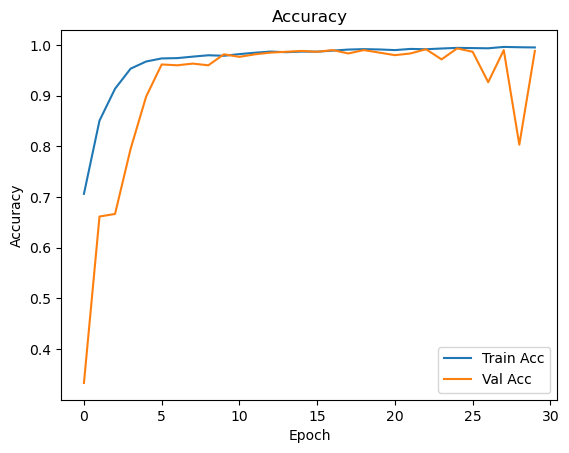

In [198]:
# #Loss
# plt.figure(figsize=(12, 4))
# plt.subplot(1, 2, 1)
# plt.plot(history.history['loss'], label='Train Loss')
# plt.plot(history.history['val_loss'], label='Val Loss')
# plt.title('Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()

# #Accuracy
# plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# model predictions
y_pred = (model.predict(X_test) > 0.5).astype(int)

19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 396ms/step


In [ ]:
# classification report
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.975     0.980     0.978       200
           1      0.990     0.988     0.989       400

    accuracy                          0.985       600
   macro avg      0.983     0.984     0.983       600
weighted avg      0.985     0.985     0.985       600



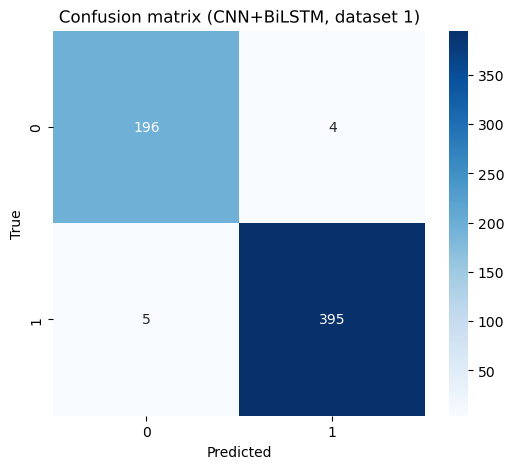

In [ ]:
import seaborn as sns
# confusion matrix
cm_new = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_new, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion matrix (CNN+BiLSTM, dataset 1)')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

In [ ]:
# predicted probabilities
y_probs = model.predict(X_test)

19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 385ms/step


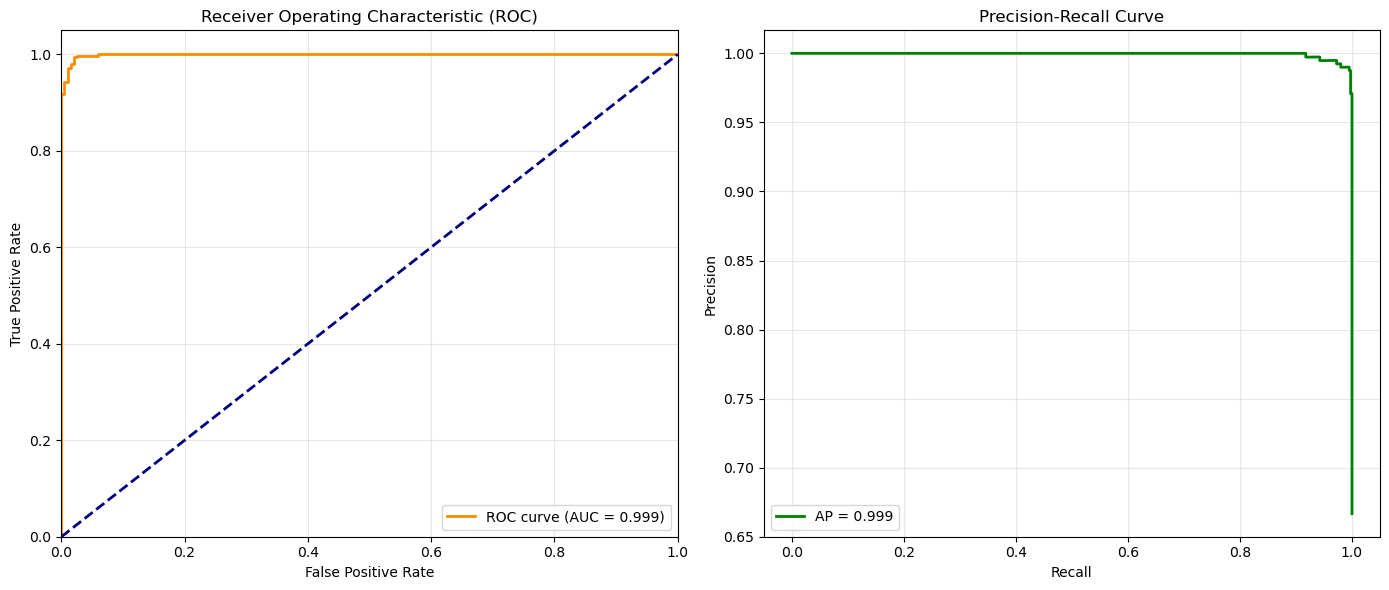

In [210]:
plt.figure(figsize=(14, 6))

# ROC curve
fpr, tpr, thresholds_roc = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

# Precision-Recall curve
precision, recall, thresholds_pr = precision_recall_curve(y_test, y_probs)
avg_precision = average_precision_score(y_test, y_probs)

plt.subplot(1, 2, 2)
plt.plot(recall, precision, color='green', lw=2, label=f'AP = {avg_precision:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [220]:
auc_score = roc_auc_score(y_test, y_probs)

print(f"Exact AUC: {auc_score:.6f}")

Exact AUC: 0.998950


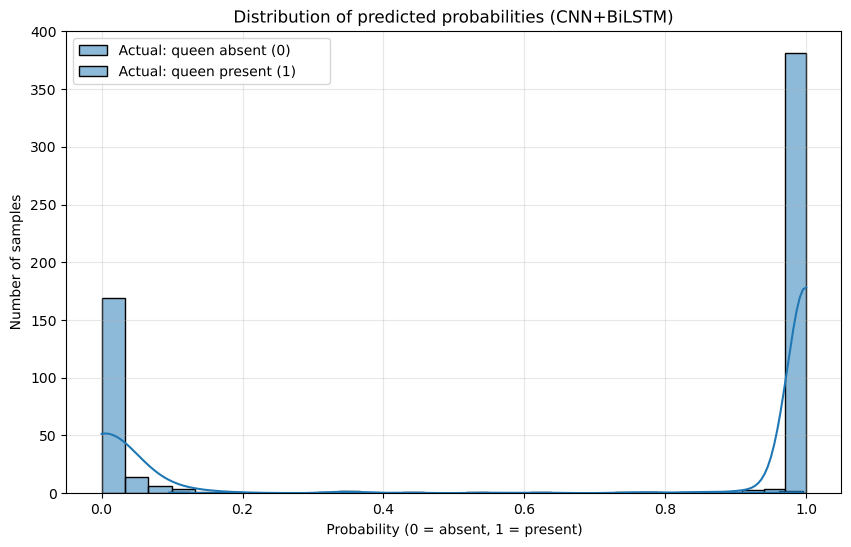

In [211]:
# Histogram of model confidence
plt.figure(figsize=(10, 6))

sns.histplot(y_probs[y_test == 0], color='red', label='Actual: queen absent (0)', kde=True, bins=30, alpha=0.5)
sns.histplot(y_probs[y_test == 1], color='blue', label='Actual: queen present (1)', kde=True, bins=30, alpha=0.5)

plt.title('Distribution of predicted probabilities (CNN+BiLSTM)')
plt.xlabel('Probability (0 = absent, 1 = present)')
plt.ylabel('Number of samples')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [212]:
# False positive analysis
results_df = test_df.copy().reset_index(drop=True)
results_df["probability"] = y_probs.flatten()
results_df["prediction"] = (y_probs > 0.5).astype(int).flatten()

false_positives = results_df[(results_df["label"] == 0) & (results_df["prediction"] == 1)]

print(f"Number of false positives: {len(false_positives)}")

if not false_positives.empty:
    print("\nExample files wrongly classified as queen present (top 5 by confidence):")
    print(false_positives.sort_values(by="probability", ascending=False).head(5)[["file", "probability"]])
else:
    print("No false positives!")

Number of false positives: 4

Example files wrongly classified as queen present (top 5 by confidence):
                                                  file  probability
212  Hive1 31_05_2018_NO_QueenBee____00_20_00_chunk...     0.994980
134  Hive1 31_05_2018_NO_QueenBee____00_20_00_chunk...     0.978106
425  Hive1 31_05_2018_NO_QueenBee____00_10_00_chunk...     0.870446
590  Hive1 31_05_2018_NO_QueenBee____05_00_00_chunk...     0.765295


In [ ]:
model.save("temp_bee_model_analysis.h5")
model_size_mb = os.path.getsize("temp_bee_model_analysis.h5") / (1024 * 1024)
print(f"Model size on disk: {model_size_mb:.2f} MB")

sample_batch = X_test[:100]

start_time = time.time()
_ = model.predict(sample_batch, verbose=0)
end_time = time.time()

total_time = end_time - start_time
time_per_sample_ms = (total_time / 100) * 1000

print(f"Processing time for 100 samples: {total_time:.4f} s")
print(f"Average time per sample: {time_per_sample_ms:.2f} ms")

if os.path.exists("temp_bee_model_analysis.h5"):
    os.remove("temp_bee_model_analysis.h5")

Model size on disk: 13.64 MB
Processing time for 100 samples: 1.3385 s
Average time per sample: 13.38 ms


___

**MLP**

In [ ]:
# LPC coefficients (17 coefficients, same sampling rate as in the hybrid model)
def extract_lpc_features(file_path, order=16, sr=32000):
    y, sr = librosa.load(file_path, sr=sr)

    # same length as in the spectrograms (10 s)
    target_len = sr * 10
    if len(y) < target_len:
        y = np.pad(y, (0, target_len - len(y)))
    else:
        y = y[:target_len]

    return librosa.lpc(y, order=order)

In [ ]:

def build_lpc_from_df(df, audio_dir, order=16):
    X = []
    y = []

    for _, row in df.iterrows():
        wav_name = row["file"].replace(".npy", ".wav")
        wav_path = os.path.join(audio_dir, wav_name)

        lpc = extract_lpc_features(wav_path, order=order)

        X.append(lpc)
        y.append(row["label"])

    return np.array(X), np.array(y)

In [ ]:
# assign the coefficients to the matching recordings (same train/val/test split as for the hybrid model)
X_lpc_train, y_lpc_train = build_lpc_from_df(train_df, audio)
X_lpc_val,   y_lpc_val   = build_lpc_from_df(val_df,   audio)
X_lpc_test,  y_lpc_test  = build_lpc_from_df(test_df,  audio)

In [ ]:
# save the splits
np.save("X_lpc_train.npy", X_lpc_train)
np.save("X_lpc_val.npy", X_lpc_val)
np.save("X_lpc_test.npy", X_lpc_test)
np.save("y_lpc_train.npy", y_lpc_train)
np.save("y_lpc_val.npy", y_lpc_val)
np.save("y_lpc_test.npy", y_lpc_test)

In [ ]:
# load the saved splits
X_lpc_train = np.load("X_lpc_train.npy")
y_lpc_train = np.load("y_lpc_train.npy")
X_lpc_val = np.load("X_lpc_val.npy")
y_lpc_val = np.load("y_lpc_val.npy")
X_lpc_test = np.load("X_lpc_test.npy")
y_lpc_test = np.load("y_lpc_test.npy")

In [ ]:
# MLP architecture and hyperparameters
lpc_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_lpc_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

lpc_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# train the MLP
history_lpc = lpc_model.fit(
    X_lpc_train, y_lpc_train,
    validation_data=(X_lpc_val, y_lpc_val),
    epochs=30,
    batch_size=32,
    verbose=1
)

Epoch 1/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8604 - loss: 0.3383 - val_accuracy: 0.8600 - val_loss: 0.3439
Epoch 2/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8642 - loss: 0.3324 - val_accuracy: 0.8583 - val_loss: 0.3460
Epoch 3/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8640 - loss: 0.3306 - val_accuracy: 0.8617 - val_loss: 0.3324
Epoch 4/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8685 - loss: 0.3210 - val_accuracy: 0.8583 - val_loss: 0.3273
Epoch 5/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8656 - loss: 0.3207 - val_accuracy: 0.8683 - val_loss: 0.3199
Epoch 6/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8717 - loss: 0.3110 - val_accuracy: 0.8750 - val_loss: 0.3129
Epoch 7/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8742 - loss: 0.3090 - val_accuracy: 0.8600 - val_loss: 0.3091
Epoch 8/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8698 - loss: 0.3003 - val_accuracy: 0.

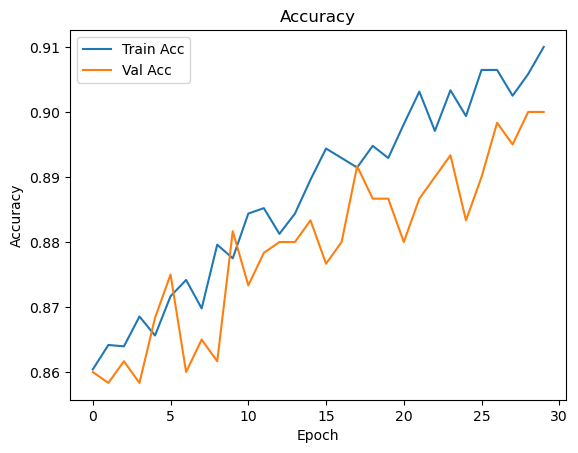

In [197]:
# # Loss
# plt.figure(figsize=(12, 4))
# plt.subplot(1, 2, 1)
# plt.plot(history_lpc.history['loss'], label='Train Loss')
# plt.plot(history_lpc.history['val_loss'], label='Val Loss')
# plt.title('Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()

# # Accuracy
# plt.subplot(1, 2, 2)
plt.plot(history_lpc.history['accuracy'], label='Train Acc')
plt.plot(history_lpc.history['val_accuracy'], label='Val Acc')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# MLP classification report
y_lpc_pred = (lpc_model.predict(X_lpc_test) > 0.5).astype(int)

print(classification_report(y_lpc_test, y_lpc_pred, digits=3))

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
              precision    recall  f1-score   support

           0      0.920     0.860     0.889       200
           1      0.932     0.963     0.947       400

    accuracy                          0.928       600
   macro avg      0.926     0.911     0.918       600
weighted avg      0.928     0.928     0.928       600



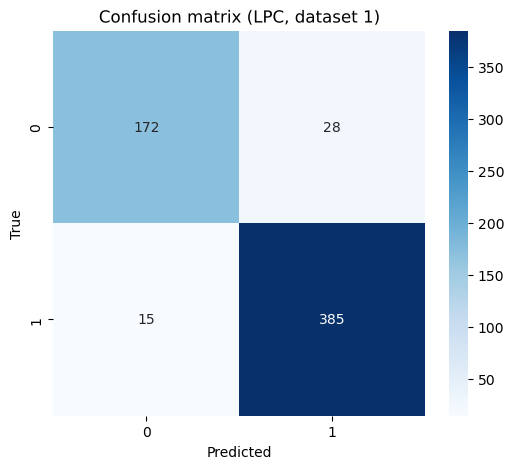

In [ ]:
import seaborn as sns
# confusion matrix
cm_lpc = confusion_matrix(y_lpc_test, y_lpc_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_lpc, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion matrix (LPC, dataset 1)')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

In [ ]:
# probabilities predicted by the MLP
y_lpc_probs = lpc_model.predict(X_lpc_test)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


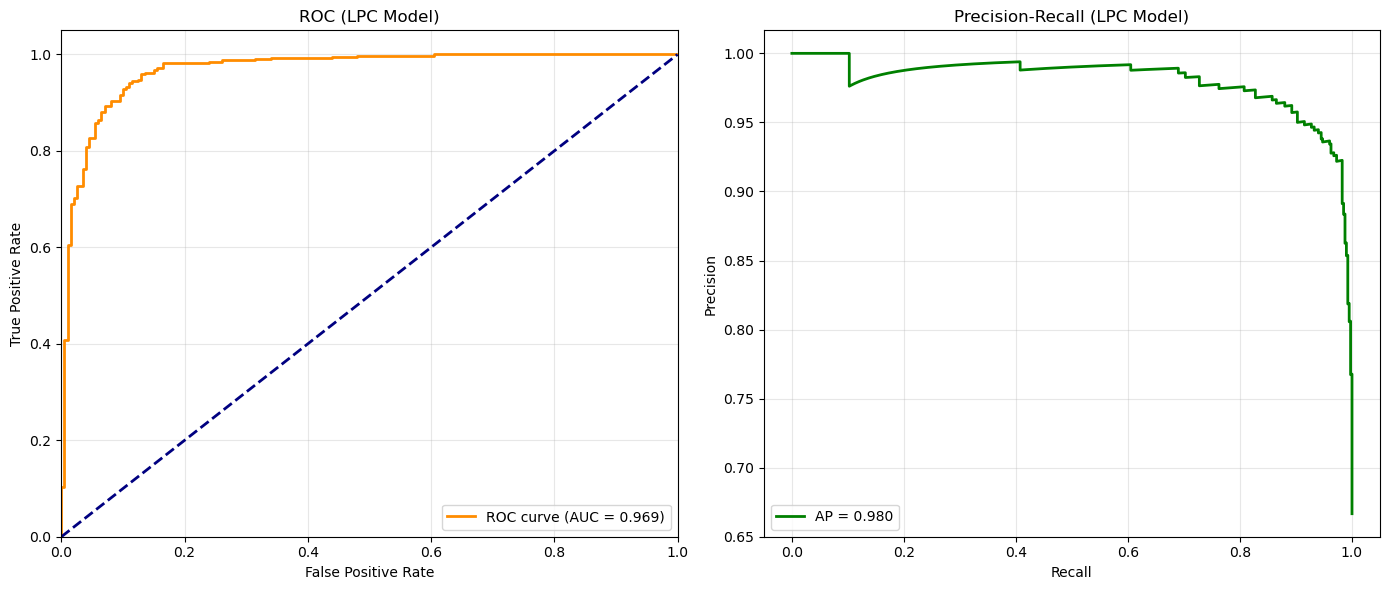

In [215]:
plt.figure(figsize=(14, 6))

# ROC curve (LPC)
fpr, tpr, thresholds_roc = roc_curve(y_lpc_test, y_lpc_probs)
roc_auc = auc(fpr, tpr)

plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC (LPC Model)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

# Precision-Recall curve (LPC)
precision, recall, thresholds_pr = precision_recall_curve(y_lpc_test, y_lpc_probs)
avg_precision = average_precision_score(y_lpc_test, y_lpc_probs)

plt.subplot(1, 2, 2)
plt.plot(recall, precision, color='green', lw=2, label=f'AP = {avg_precision:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall (LPC Model)')
plt.legend(loc="lower left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

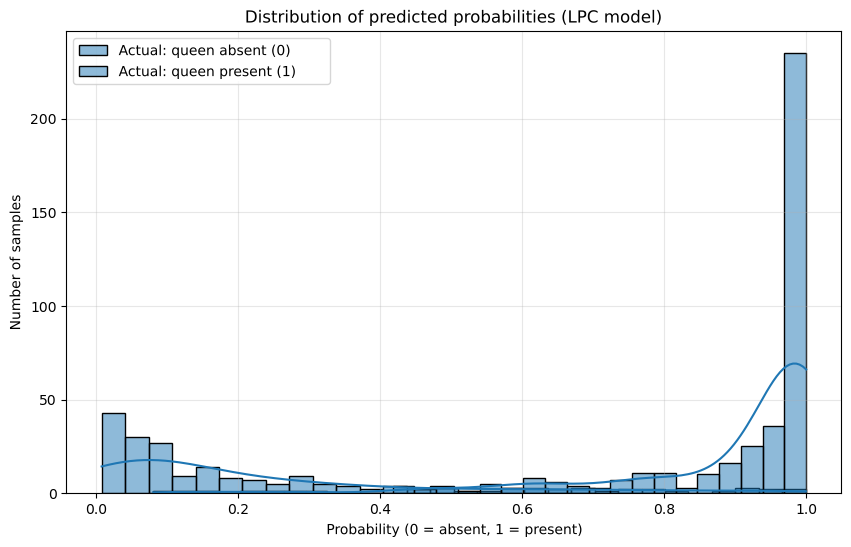

In [216]:
# Histogram of model confidence (LPC)
plt.figure(figsize=(10, 6))

sns.histplot(y_lpc_probs[y_lpc_test == 0], color='red', label='Actual: queen absent (0)', kde=True, bins=30, alpha=0.5)
sns.histplot(y_lpc_probs[y_lpc_test == 1], color='blue', label='Actual: queen present (1)', kde=True, bins=30, alpha=0.5)

plt.title('Distribution of predicted probabilities (LPC model)')
plt.xlabel('Probability (0 = absent, 1 = present)')
plt.ylabel('Number of samples')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [217]:
# False positive analysis
results_lpc_df = test_df.copy().reset_index(drop=True)
results_lpc_df["probability"] = y_lpc_probs.flatten()
results_lpc_df["prediction"] = (y_lpc_probs > 0.5).astype(int).flatten()

false_positives_lpc = results_lpc_df[(results_lpc_df["label"] == 0) & (results_lpc_df["prediction"] == 1)]

print(f"Number of false positives (LPC): {len(false_positives_lpc)}")

if not false_positives_lpc.empty:
    print("\nExample files wrongly classified as queen present by LPC (top 5 by confidence):")
    print(false_positives_lpc.sort_values(by="probability", ascending=False).head(5)[["file", "probability"]])
else:
    print("No false positives in the LPC model!")

Number of false positives (LPC): 28

Example files wrongly classified as queen present by LPC (top 5 by confidence):
                                                  file  probability
154  Hive1 31_05_2018_NO_QueenBee____02_50_00_chunk...     0.999525
375  Hive1 31_05_2018_NO_QueenBee____02_50_00_chunk...     0.989877
394  Hive1 31_05_2018_NO_QueenBee____00_20_00_chunk...     0.965702
241  Hive1 31_05_2018_NO_QueenBee____05_00_00_chunk...     0.936086
42   Hive1 31_05_2018_NO_QueenBee____01_20_00_chunk...     0.928381


In [218]:
# Computational cost of the model
lpc_model.save("temp_lpc_model.h5")
model_size_mb = os.path.getsize("temp_lpc_model.h5") / (1024 * 1024)
print(f"LPC model size on disk: {model_size_mb:.4f} MB")

sample_batch = X_lpc_test[:100]

start_time = time.time()
_ = lpc_model.predict(sample_batch, verbose=0)
end_time = time.time()

total_time = end_time - start_time
time_per_sample_ms = (total_time / 100) * 1000

print(f"Processing time for 100 samples: {total_time:.4f} s")
print(f"Average time per sample: {time_per_sample_ms:.4f} ms")

if os.path.exists("temp_lpc_model.h5"):
    os.remove("temp_lpc_model.h5")

LPC model size on disk: 0.0684 MB
Processing time for 100 samples: 0.0845 s
Average time per sample: 0.8447 ms


**Check for data leakage**

In [196]:
# check that no file appears in more than one set
train_files = set(train_df["file"])
test_files  = set(test_df["file"])

len(train_files.intersection(test_files))

0